# Bill Color Detection (Version 2)

In [22]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the image
image = cv2.imread('Images/peso-bill.png')
if image is None:
    raise FileNotFoundError("Image not found.")

image = cv2.resize(image, (640, 480))  # Resize if needed

# RGB (for display) and HSV (for color detection)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

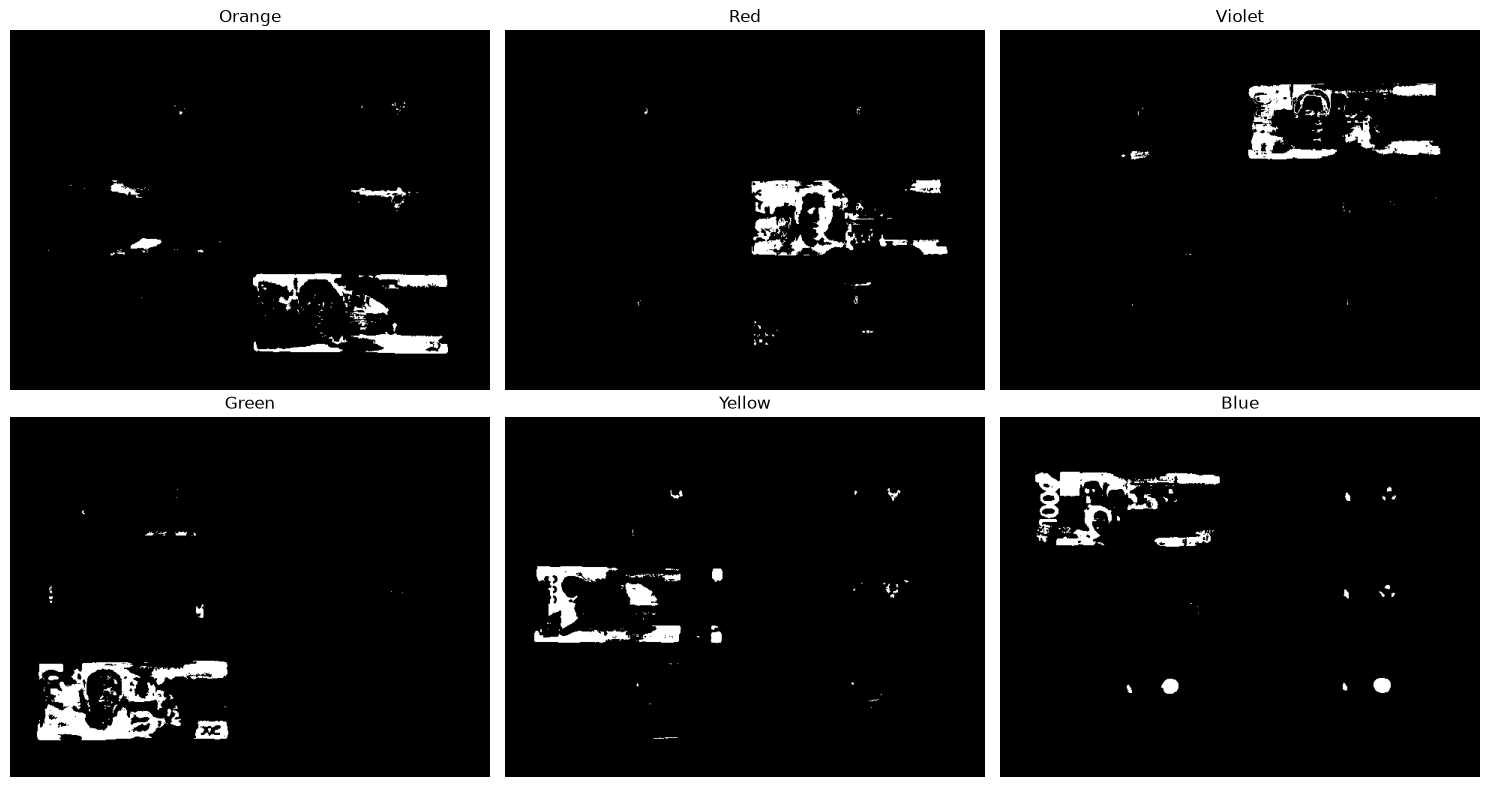

In [23]:
# name -> HSV range(s), box color, peso value
BILLS = {
    "Orange": dict(ranges=[((10, 100, 100), (17, 255, 255))],  box=(255, 140, 0),  value=20),
    "Red":    dict(ranges=[((175, 100, 100), (180, 255, 255))], box=(255, 0, 0),    value=50),
    "Violet": dict(ranges=[((140, 40, 50), (162, 255, 220))],  box=(148, 0, 211),  value=100),
    "Green":  dict(ranges=[((40, 35, 40), (60, 255, 255))],    box=(0, 150, 0),    value=200),
    "Yellow": dict(ranges=[((18, 90, 90), (27, 255, 255))],    box=(255, 215, 0),  value=500),
    "Blue":   dict(ranges=[((92, 60, 50), (114, 255, 220))],   box=(0, 0, 255),    value=1000),
}


def build_mask(hsv_img, ranges):
    """OR together one or more HSV ranges (red wraps around 0/180) into a single mask."""
    masks = [cv2.inRange(hsv_img, np.array(lo), np.array(hi)) for lo, hi in ranges]
    return np.bitwise_or.reduce(masks)


# Preview the raw color mask for every denomination
fig, axs = plt.subplots(2, 3, figsize=(15, 8))
for ax, (name, info) in zip(axs.ravel(), BILLS.items()):
    ax.imshow(build_mask(hsv, info["ranges"]), cmap="gray")
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [24]:
h, w = image.shape[:2]

# Scale kernel size and minimum blob size to the image resolution
k_size = max(15, int(min(h, w) * 0.06))
k_size += (k_size % 2 == 0)          # kernel size must be odd
close_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_size, k_size))
noise_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
min_area = int(h * w * 0.015)        # ignore blobs smaller than ~1.5% of the image


def clean_mask(mask):
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, noise_kernel)                 # remove speckle noise
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, close_kernel, iterations=2)  # bridge gaps
    return cv2.dilate(mask, close_kernel, iterations=1)                         # grow to full bill size


detections = []  # (name, value, (x, y, box_w, box_h))
for name, info in BILLS.items():
    mask = clean_mask(build_mask(hsv, info["ranges"]))
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    detections += [(name, info["value"], cv2.boundingRect(c))
                   for c in contours if cv2.contourArea(c) >= min_area]

print(f"Detected {len(detections)} bill(s).")

Detected 6 bill(s).


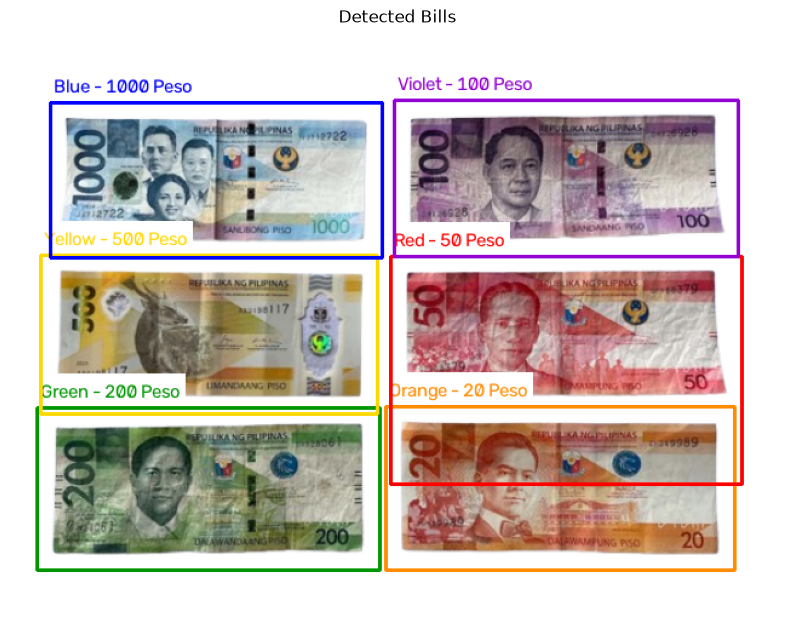

Detected bills:
  Orange: 20 Peso
  Red: 50 Peso
  Violet: 100 Peso
  Green: 200 Peso
  Yellow: 500 Peso
  Blue: 1000 Peso

Total count: 6
Total value: P1870


In [25]:
# Draw a labeled box on every detected bill
output_img = image_rgb.copy()

for name, value, (x, y, bw, bh) in detections:
    color = BILLS[name]["box"]
    cv2.rectangle(output_img, (x, y), (x + bw, y + bh), color, 2)

    text = f"{name} - {value} Peso"
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
    ty = max(y - 8, th + 4)
    cv2.rectangle(output_img, (x, ty - th - 6), (x + tw + 6, ty + 4), (255, 255, 255), -1)
    cv2.putText(output_img, text, (x + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)

plt.figure(figsize=(10, 8))
plt.imshow(output_img)
plt.title("Detected Bills")
plt.axis("off")
plt.show()

# Summary + total peso value
print("Detected bills:")
for name, value, _ in detections:
    print(f"  {name}: {value} Peso")

print(f"\nTotal count: {len(detections)}")
print(f"Total value: P{sum(v for _, v, _ in detections)}")